#### 04C · ¿Sirve el gradiente reconstruido desde las PCs de presión truncadas?
En simulación el PVAR solo da PCs de presión. Si el gradiente se calcula **después**, sobre el campo de presión reconstruido con esas PCs, la no linealidad la pone la física y no el VAR. Pero truncar suaviza el campo, y las bajas pequeñas (tipo Juliette) viven en las escalas pequeñas.

**Pregunta:** ¿el gradiente reconstruido conserva capacidad predictiva **en los temporales**, aunque no se parezca al gradiente real?

- Campo de presión 6-horario 1985–2025 → PCA propia (100 PCs) y gradiente al cuadrado (misma fórmula que `bluemath spatial_gradient`, vectorizada).
- PCA del gradiente **real** (50 PCs) = los EOFs a los que se proyecta todo.
- Gradiente reconstruido con: las 30 PCs seleccionadas (lo que simula el PVAR hoy) y las K primeras (30, 50, 100).
- XGB igual que en producción (lags 0–36 h, ajuste 1985–2015, test 2016–2025), **entrenado con el mismo gradiente que se usa en test** (en simulación solo habrá gradiente reconstruido).
- Métricas de **extremos**, no solo correlación: pico de cada temporal, Juliette, q99 de ŷ.

In [1]:
import time
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import pickle

from sklearn.decomposition import PCA
from xgboost import XGBRegressor
from scipy.signal import find_peaks
from utils.pit.piece_wise_marginal import from_normal

In [2]:
#### Configuración
point = "p102"
FIELD_PATH = "/lustre/geocean/WORK/users/alonsoap/projects/TWINPEACS/02_Emulator_Testing/daily_atmospheric/outputs/data/era5_mslp_grad_1985_2026_1deg_hourly.zarr"
VAR, LAT, LON = "msl", "latitude", "longitude"
SQRT_GRAD = False                                       # False = gradiente al cuadrado (como spatial_gradient); True = módulo
N_SLP, N_GRAD = 100, 50
K_LIST = ["sel30", 30, 50, 100]                         # "sel30" = las 30 PCs que simula el PVAR
LAGS = [0, 6, 12, 18, 24, 30, 36]
SITIO = (39.6, 3.4)                                     # punto cercano a Cala Millor para el diagnóstico del campo

In [3]:
#### Oleaje: Z 6-horaria (media centrada de 6 h, como en 04B) y vuelta a metros
tr_ = pickle.load(open(f"outputs/marginal/transformacion_{point}.pkl", "rb"))
marg, harm_z = tr_["marg"], tr_["harm_z"]
def hs_desde_z(z):
    zz = pd.DataFrame({"VHM0": z.values, "VTM02": 0.0}, index=z.index)
    z0 = harm_z.inverse_transform(zz)["VHM0"].clip(-6.36, 6.36)
    return pd.Series(marg["VHM0"].ppf(from_normal(z0).values), index=z.index)

resid = pd.read_csv(f"outputs/xgb_pit_{point}/residuos_horarios.csv", index_col=0, parse_dates=True)
z6 = resid["z"].rolling("6h", center=True).mean()
z6 = z6[z6.index.hour.isin([0, 6, 12, 18])].loc["1985":"2025"]
pcs_sel = pd.read_csv("outputs/pca/pcs_msl_sel_6h.csv", index_col=0, parse_dates=True)
SEL = [int(c.split("PC")[1]) - 1 for c in pcs_sel.columns]       # índices (base 0) de las 30 PCs seleccionadas
print(len(z6), SEL)

59900 [3, 0, 2, 10, 5, 1, 33, 7, 26, 37, 16, 29, 12, 41, 35, 44, 11, 22, 42, 40, 31, 17, 34, 49, 6, 19, 20, 4, 23, 8]


In [4]:
#### Campo de presión 6-horario 1985–2025
ds = xr.open_zarr(FIELD_PATH)[VAR].rename(valid_time="time").sel(time=slice("1985-01-01", "2025-12-31"))
ds = ds.sel(time=ds.time.dt.hour.isin([0, 6, 12, 18])).transpose("time", LAT, LON)
P = ds.values.astype("float32")                                # (T, ny, nx)
T_, ny, nx = P.shape
tiempo = pd.DatetimeIndex(ds.time.values)
lat_rad = np.deg2rad(np.abs(ds[LAT].values))
print(P.shape, f"{P.nbytes / 1e9:.1f} GB")

(59900, 30, 60) 0.4 GB


In [5]:
#### Gradiente: misma fórmula que bluemath spatial_gradient, vectorizada en el tiempo (sin bordes)
def gradiente(F):
    """F: (n, ny, nx) → (n, (ny-2)·(nx-2)) gradiente al cuadrado (o su raíz)."""
    c = F[:, 1:-1, 1:-1]
    l = np.roll(F, -1, axis=2)[:, 1:-1, 1:-1]; r = np.roll(F, 1, axis=2)[:, 1:-1, 1:-1]
    u = np.roll(F, -1, axis=1)[:, 1:-1, 1:-1]; d = np.roll(F, 1, axis=1)[:, 1:-1, 1:-1]
    cphi = np.cos(lat_rad[1:-1])[None, :, None]
    g = (((c - l) / cphi) ** 2 + ((r - c) / cphi) ** 2) / 2 + ((c - d) ** 2 + (u - c) ** 2) / 2
    if SQRT_GRAD:
        g = np.sqrt(g)
    return g.reshape(len(F), -1).astype("float32")

def por_bloques(fn, n, paso=4000):
    return np.concatenate([fn(slice(i, min(i + paso, n))) for i in range(0, n, paso)])

In [6]:
#### PCA de la presión (100) y del gradiente REAL (50)
t = time.time()
X = P.reshape(T_, -1)
mu_p = X.mean(0)
pca_p = PCA(N_SLP, svd_solver="randomized", random_state=0).fit(X - mu_p)
pcs_p = pca_p.transform(X - mu_p)                                # (T, 100)
print(f"PCA presión: {pca_p.explained_variance_ratio_[:30].sum():.3f} var. con 30 primeras, "
      f"{pca_p.explained_variance_ratio_[SEL].sum():.3f} con las 30 seleccionadas ({time.time() - t:.0f} s)")

G = por_bloques(lambda s: gradiente(P[s]), T_)
mu_g = G.mean(0)
pca_g = PCA(N_GRAD, svd_solver="randomized", random_state=0).fit(G - mu_g)
pcs_g_real = pd.DataFrame(pca_g.transform(G - mu_g), index=tiempo, columns=[f"grad_PC{i + 1}" for i in range(N_GRAD)])
print(f"PCA gradiente: {pca_g.explained_variance_ratio_.sum():.3f} var. con {N_GRAD} ({time.time() - t:.0f} s)")

PCA presión: 0.988 var. con 30 primeras, 0.965 con las 30 seleccionadas (4 s)
PCA gradiente: 0.845 var. con 50 (9 s)


In [7]:
#### Comprobación: ¿mis PCs se parecen a las tuyas? (|corr| ≈ 1 → mismo campo y mismo preprocesado)
p_mia = pd.DataFrame(pcs_p[:, SEL], index=tiempo, columns=pcs_sel.columns)
comun = p_mia.index.intersection(pcs_sel.index)
cc = [abs(np.corrcoef(p_mia.loc[comun, c_], pcs_sel.loc[comun, c_])[0, 1]) for c_ in pcs_sel.columns]
print("presión, |corr| por PC seleccionada:", np.round(cc, 2))
try:
    g_tuyas = pd.read_csv("outputs/pca/pcs_msl_gradient.csv", index_col=0, parse_dates=True).reindex(tiempo)
    print("gradiente, |corr| PC1–5:", [round(abs(pcs_g_real.iloc[:, i].corr(g_tuyas.iloc[:, i])), 2) for i in range(5)])
except FileNotFoundError:
    pass
print("Si salen bajas: otro preprocesado (estandarización, pesos por latitud, periodo). Las PCs que uso aquí son las mías, coherentes entre sí.")

presión, |corr| por PC seleccionada: [0.86 0.77 0.91 0.78 0.85 0.7  0.32 0.71 0.54 0.29 0.63 0.17 0.74 0.13
 0.22 0.06 0.67 0.66 0.11 0.05 0.28 0.76 0.42 0.12 0.71 0.33 0.33 0.89
 0.57 0.8 ]
gradiente, |corr| PC1–5: [np.float64(0.9), np.float64(0.64), np.float64(0.45), np.float64(0.4), np.float64(0.01)]
Si salen bajas: otro preprocesado (estandarización, pesos por latitud, periodo). Las PCs que uso aquí son las mías, coherentes entre sí.


In [8]:
#### Reconstrucción desde TUS 30 PCs (las que simula el PVAR): regresión del campo sobre ellas
p_tuyas = pcs_sel.reindex(tiempo)
ok = p_tuyas.notna().all(axis=1).values
print(f"pasos sin tus PCs: {(~ok).sum()}")
A = np.c_[np.ones(ok.sum()), p_tuyas.values[ok]]
B, *_ = np.linalg.lstsq(A, X[ok], rcond=None)                     # (31, npts): media + un patrón por PC
r2 = 1 - ((X[ok] - A @ B) ** 2).sum() / ((X[ok] - X[ok].mean(0)) ** 2).sum()
print(f"varianza del campo explicada por tus 30 PCs: {r2:.3f}")
p_mia = p_tuyas.fillna(0)                                         # predictores del XGB = los de producción

pasos sin tus PCs: 0
varianza del campo explicada por tus 30 PCs: 0.959


In [9]:
#### Gradiente reconstruido → proyectado en los EOFs del gradiente real
iy = np.abs(ds[LAT].values[1:-1] - SITIO[0]).argmin(); ix = np.abs(ds[LON].values[1:-1] - SITIO[1]).argmin()
j_sitio = iy * (nx - 2) + ix
g_sitio_real = G[:, j_sitio]
fuertes = g_sitio_real > np.quantile(g_sitio_real, 0.95)

pcs_g_rec, diag = {}, {}
for K in K_LIST:
    t = time.time()
    if K == "sel30":                                              # tus 30 PCs, vía regresión
        def rec(s):
            A_ = np.c_[np.ones(s.stop - s.start), p_mia.values[s]]
            return gradiente((A_ @ B).astype("float32").reshape(-1, ny, nx))
        n_pc = p_mia.shape[1]
    else:                                                         # K primeras de mi PCA
        E_ = pca_p.components_[:K]
        def rec(s):
            return gradiente((mu_p + pcs_p[s][:, :K] @ E_).reshape(-1, ny, nx))
        n_pc = K
    Gk = por_bloques(rec, T_)
    pcs_g_rec[K] = pd.DataFrame(pca_g.transform(Gk - mu_g), index=tiempo, columns=pcs_g_real.columns)
    gs = Gk[:, j_sitio]
    diag[K] = {"nº PCs": n_pc,
               "p99 dominio rec/real": np.quantile(Gk, 0.99) / np.quantile(G, 0.99),
               "p99 sitio rec/real": np.quantile(gs, 0.99) / np.quantile(g_sitio_real, 0.99),
               "corr sitio": np.corrcoef(gs, g_sitio_real)[0, 1],
               "corr espacial (días fuertes)": np.mean([np.corrcoef(Gk[i], G[i])[0, 1] for i in np.flatnonzero(fuertes)[::5]])}
    del Gk
    print(f"{K}: {time.time() - t:.0f} s")
print(pd.DataFrame(diag).T.round(3).to_string())

sel30: 3 s
30: 3 s
50: 3 s
100: 3 s
       nº PCs  p99 dominio rec/real  p99 sitio rec/real  corr sitio  corr espacial (días fuertes)
sel30    30.0                 0.709               0.647       0.727                         0.744
30       30.0                 0.809               0.619       0.659                         0.807
50       50.0                 0.866               0.760       0.757                         0.864
100     100.0                 0.924               0.818       0.825                         0.924


In [10]:
#### XGB como en producción: presión (30 seleccionadas) + gradiente; entrenado y evaluado con el MISMO tipo de gradiente
PAR = dict(n_estimators=300, learning_rate=0.05, max_depth=6, min_child_weight=200, subsample=0.8,
           colsample_bytree=0.8, tree_method="hist", n_jobs=8, random_state=0)
def lagged(p):
    Xl = pd.concat({f"l{l}": p.shift(freq=pd.Timedelta(hours=l)) for l in LAGS}, axis=1).reindex(p.index)
    Xl.columns = [f"{c_}_l{l[1:]}" for l, c_ in Xl.columns]
    return Xl

def ajusta(P_):
    d = pd.concat([lagged(P_), z6.rename("y")], axis=1).dropna()
    tr = d.index < "2016-01-01"
    m = XGBRegressor(**PAR).fit(d.loc[tr].drop(columns="y"), d.loc[tr, "y"])
    return pd.Series(m.predict(d.loc[~tr].drop(columns="y")), index=d.index[~tr])

variantes = {"presión (30)": p_mia, "+ gradiente real": p_mia.join(pcs_g_real)}
variantes.update({f"+ gradiente rec. {K}": p_mia.join(pcs_g_rec[K]) for K in K_LIST})
pred = {}
for nom, P_ in variantes.items():
    t = time.time(); pred[nom] = ajusta(P_); print(f"{nom} ({time.time() - t:.0f} s)")

presión (30) (3 s)
+ gradiente real (9 s)
+ gradiente rec. sel30 (9 s)
+ gradiente rec. 30 (9 s)
+ gradiente rec. 50 (9 s)
+ gradiente rec. 100 (9 s)


In [11]:
print("z6  :", z6.dropna().index[[0, -1]])
print("campo:", tiempo[[0, -1]])
print("z6 NaN en 2016–2025:", z6.loc["2016":].isna().mean().round(3))

z6  : DatetimeIndex(['1985-01-01 00:00:00', '2025-12-31 18:00:00'],
              dtype='datetime64[us]', name='time', freq=None)
campo: DatetimeIndex(['1985-01-01 00:00:00', '2025-12-31 18:00:00'],
              dtype='datetime64[ns]', freq=None)
z6 NaN en 2016–2025: 0.0


In [12]:
#### Métricas: correlación y, sobre todo, temporales
y_te = z6.loc["2016":"2025"]
hs_obs = hs_desde_z(y_te)
u = hs_obs.quantile(0.99)
picos = hs_obs.index[find_peaks(hs_obs.values, height=u, distance=12)[0]]        # picos > q99, separados 72 h
win = pd.Timedelta("24h")
jul = slice("2023-02-25", "2023-03-03")

filas, tabla_picos = {}, {"obs": [hs_obs.loc[t_] for t_ in picos]}
for nom, f in pred.items():
    h = hs_desde_z(f)
    pk = np.array([h.loc[t_ - win:t_ + win].max() for t_ in picos])
    ob = np.array(tabla_picos["obs"])
    tabla_picos[nom] = pk
    top5 = np.argsort(ob)[-5:]
    filas[nom] = {"corr test": f.corr(y_te.reindex(f.index)),
                  "q99 ŷ / q99 obs (m)": h.quantile(0.99) / hs_obs.quantile(0.99),
                  "pico ŷ/obs (media)": np.mean(pk / ob),
                  "pico ŷ/obs (5 mayores)": np.mean(pk[top5] / ob[top5]),
                  "temporales con ŷ < 0.7·obs": int((pk < 0.7 * ob).sum()),
                  "Juliette ŷ (m)": h.loc[jul].max()}
print(f"{len(picos)} temporales en test | Juliette obs 6 h: {hs_obs.loc[jul].max():.2f} m")
display(pd.DataFrame(filas).T.round(3))
tabla_picos = pd.DataFrame(tabla_picos, index=picos.date).sort_values("obs", ascending=False)
display(tabla_picos.round(2))

49 temporales en test | Juliette obs 6 h: 5.97 m


,corr test,q99 ŷ / q99 obs (m),pico ŷ/obs (media),pico ŷ/obs (5 mayores),temporales con ŷ < 0.7·obs,Juliette ŷ (m)
presión (30),0.778,0.900,0.799,0.806,18.0,2.659
+ gradiente real,0.816,0.934,0.823,0.886,14.0,4.657
+ gradiente rec. sel30,0.811,0.919,0.822,0.780,15.0,3.137
+ gradiente rec. 30,0.816,0.913,0.799,0.787,15.0,3.477
+ gradiente rec. 50,0.821,0.925,0.828,0.867,14.0,3.855
+ gradiente rec. 100,0.820,0.923,0.818,0.929,15.0,4.588


,obs,presión (30),+ gradiente real,+ gradiente rec. sel30,+ gradiente rec. 30,+ gradiente rec. 50,+ gradiente rec. 100
2023-02-28,5.97,2.66,4.66,3.14,3.48,3.85,4.59
2017-01-21,5.63,5.80,5.87,5.23,4.70,5.76,6.28
2017-11-14,5.55,5.38,4.54,4.93,4.99,5.15,5.03
2019-11-11,5.47,2.89,3.23,3.01,3.09,3.43,3.43
2020-01-21,5.39,5.70,6.45,5.41,5.69,5.99,6.62
2017-01-17,5.23,4.40,4.65,4.76,4.46,4.61,4.48
2021-11-07,5.15,5.43,5.39,5.16,5.15,5.39,5.16
2024-02-28,5.07,3.12,3.86,3.87,3.40,3.61,3.63
2018-03-21,5.01,4.86,4.28,4.45,4.28,4.32,4.56
2016-02-16,4.87,3.20,4.18,3.19,3.65,3.97,3.96


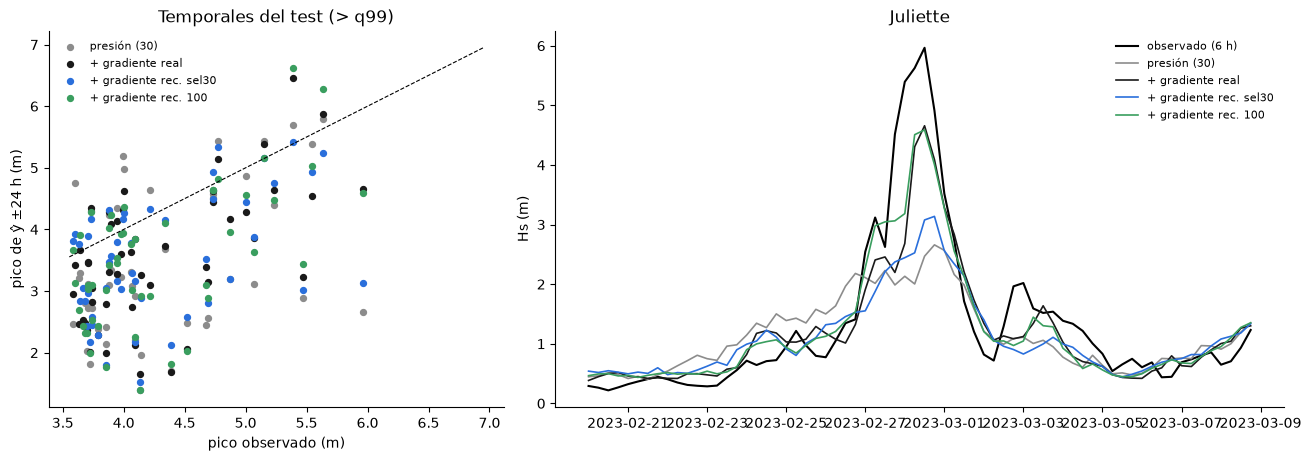

In [13]:
#### Picos: obs vs ŷ, y la ventana de Juliette
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True, gridspec_kw={"width_ratios": [1, 1.6]})
cols = dict(zip(pred, ["0.55", "0.1", "#2a6fdb", "#7aa6e8", "#d1495b", "#3a9e5f"]))
for nom in ["presión (30)", "+ gradiente real", "+ gradiente rec. sel30", f"+ gradiente rec. {K_LIST[-1]}"]:
    ax[0].scatter(tabla_picos["obs"], tabla_picos[nom], s=18, color=cols[nom], label=nom)
lim = [u, tabla_picos.max().max() * 1.05]
ax[0].plot(lim, lim, "k--", lw=0.8)
ax[0].set(xlabel="pico observado (m)", ylabel="pico de ŷ ±24 h (m)", title="Temporales del test (> q99)")
ax[0].legend(frameon=False, fontsize=8)
w_ = slice("2023-02-20", "2023-03-08")
ax[1].plot(hs_obs.loc[w_], color="k", lw=1.5, label="observado (6 h)")
for nom in ["presión (30)", "+ gradiente real", "+ gradiente rec. sel30", f"+ gradiente rec. {K_LIST[-1]}"]:
    ax[1].plot(hs_desde_z(pred[nom]).loc[w_], color=cols[nom], lw=1.2, label=nom)
ax[1].set(ylabel="Hs (m)", title="Juliette")
ax[1].legend(frameon=False, fontsize=8)
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.show()

#### Cómo leerlo
- **Diagnóstico del campo** (tabla de `diag`): p99 rec/real < 1 = la truncación debilita los gradientes fuertes. Es esperable; lo que importa es lo siguiente.
- **Capacidad predictiva**: si `+ gradiente rec. sel30` recupera buena parte del salto de `presión (30)` a `+ gradiente real` en **pico ŷ/obs** y **Juliette**, el gradiente reconstruido sirve aunque sea más débil: el XGB se entrena con él y aprende su escala.
- Si solo lo recupera con K = 100: habría que simular más PCs en el PVAR (más difícil).
- Si no lo recupera con ninguna K: las bajas pequeñas no están en las PCs de presión; el gradiente habría que simularlo aparte (y vuelve el problema de las colas del PVAR).
- Ojo: un único ajuste y una semilla; los picos individuales son orientativos, el salto de Juliette (2.6 → 5.6 m con gradiente real) no.

In [14]:
#### ¿Genera el PVAR los gradientes fuertes? Gradiente reconstruido (con B) desde las PCs SIMULADAS vs desde tus PCs históricas
import glob
from scipy.stats import skew
N_SIMS_G = 5                                                     # ← más si va rápido
def grad_desde_pcs(pcs_df):
    """PCs (tus 30, mismas columnas) → gradiente del campo reconstruido con B: serie en el sitio y muestra del dominio."""
    V = pcs_df[pcs_sel.columns].values
    def rec(s):
        return gradiente((np.c_[np.ones(s.stop - s.start), V[s]] @ B).astype("float32").reshape(-1, ny, nx))
    Gk = por_bloques(rec, len(V))
    return pd.Series(Gk[:, j_sitio], index=pcs_df.index), Gk[::4].ravel()

def resumen(g_sitio, g_dom):
    am = g_sitio.groupby(g_sitio.index.year).max()
    inv = g_sitio[g_sitio.index.month.isin([11, 12, 1, 2, 3])]
    tra = g_sitio[g_sitio.index.month.isin([3, 4, 10, 11])]
    return {"sitio q50": g_sitio.quantile(0.5), "sitio q90": g_sitio.quantile(0.9), "sitio q99": g_sitio.quantile(0.99),
            "sitio q99.9": g_sitio.quantile(0.999), "sitio asimetría": skew(g_sitio), "sitio máx. anual (mediana)": am.median(),
            "sitio q99 nov–mar": inv.quantile(0.99), "sitio q99 mar-abr/oct-nov": tra.quantile(0.99),
            "dominio q99": np.quantile(g_dom, 0.99)}

t = time.time()
filas = {"histórico (tus PCs, 1985–2025)": resumen(*grad_desde_pcs(p_mia))}
for i, fic in enumerate(sorted(glob.glob("outputs/var_6h/simulaciones/sim_*.parquet"))[:N_SIMS_G]):
    pcs_sim = pd.read_parquet(fic).astype("float64")
    pcs_sim = pcs_sim.loc[str(pcs_sim.index[0].year + 1):]       # fuera el primer año
    filas[f"PVAR sim {i:02d}"] = resumen(*grad_desde_pcs(pcs_sim))
    print(f"sim {i:02d} ({time.time() - t:.0f} s)")
tab = pd.DataFrame(filas).T
sims = tab.iloc[1:]
tab.loc["PVAR / histórico (mediana de sims)"] = sims.median() / tab.iloc[0]
display(tab.round(3))

sim 00 (8 s)
sim 01 (13 s)
sim 02 (18 s)
sim 03 (23 s)
sim 04 (28 s)


,sitio q50,sitio q90,sitio q99,sitio q99.9,sitio asimetría,sitio máx. anual (mediana),sitio q99 nov–mar,sitio q99 mar-abr/oct-nov,dominio q99
"histórico (tus PCs, 1985–2025)",3765.120,19293.136,50058.289,89894.269,3.395,97441.844,63041.887,51210.963,136566.359
PVAR sim 00,4201.300,19210.269,49195.304,84523.372,3.137,81120.703,60386.078,45480.691,134516.422
PVAR sim 01,4263.612,19700.977,48361.413,81643.351,3.077,78884.203,61357.772,44614.415,135759.859
PVAR sim 02,4262.187,19399.196,48015.779,79787.311,3.058,76540.094,59630.495,47875.797,133471.047
PVAR sim 03,4265.230,19522.074,49320.480,87794.963,3.351,77766.281,61697.482,45201.728,136286.828
PVAR sim 04,4193.760,19005.617,47703.932,78388.500,2.998,77945.516,59389.525,45974.956,134871.266
PVAR / histórico (mediana de sims),1.132,1.005,0.966,0.908,0.906,0.800,0.958,0.888,0.988


In [15]:
#### Mes a mes: q99 del gradiente en el sitio (histórico vs PVAR)
g_hist, _ = grad_desde_pcs(p_mia)
q_mes = {"histórico": g_hist.groupby(g_hist.index.month).quantile(0.99)}
for i, fic in enumerate(sorted(glob.glob("outputs/var_6h/simulaciones/sim_*.parquet"))[:N_SIMS_G]):
    pcs_sim = pd.read_parquet(fic).astype("float64")
    pcs_sim = pcs_sim.loc[str(pcs_sim.index[0].year + 1):]
    g_s, _ = grad_desde_pcs(pcs_sim)
    q_mes[f"sim {i:02d}"] = g_s.groupby(g_s.index.month).quantile(0.99)
q_mes = pd.DataFrame(q_mes)
q_mes["PVAR/hist"] = q_mes.iloc[:, 1:].median(axis=1) / q_mes["histórico"]
display(q_mes[["histórico", "PVAR/hist"]].round(2).T)

#### Y la varianza de cada PC por mes: ¿el PVAR la reproduce en primavera/otoño?
sd_h = p_mia.groupby(p_mia.index.month).std()
sd_s = pcs_sim.groupby(pcs_sim.index.month).std()               # última simulación cargada
print("std PVAR / std histórico, mediana sobre las 30 PCs, por mes:")
print((sd_s / sd_h).median(axis=1).round(2).to_string())

,1,2,3,4,5,6,7,8,9,10,11,12
histórico,70498.15,60861.86,57761.79,42707.82,29840.76,15388.36,11915.09,13518.69,24008.23,40094.78,58696.84,65206.28
PVAR/hist,0.93,0.95,0.85,0.98,0.87,0.98,0.98,0.97,0.80,0.84,0.89,1.01


std PVAR / std histórico, mediana sobre las 30 PCs, por mes:
1     1.03
2     1.01
3     0.99
4     1.01
5     1.00
6     0.99
7     0.99
8     1.02
9     1.00
10    0.99
11    1.00
12    1.02


In [16]:
#### Diferencias de presión en el sitio (lineales en las PCs): std y curtosis por mes, histórico vs PVAR
from scipy.stats import kurtosis
yy, xx = iy + 1, ix + 1                                            # sitio en la malla completa
pts = {"e": (0, 1), "w": (0, -1), "n": (1, 0), "s": (-1, 0)}
cols5 = {k: (yy + dy) * nx + (xx + dx) for k, (dy, dx) in pts.items()}
Bp = B[:, list(cols5.values())]                                    # (31, 4)
cphi = np.cos(lat_rad[yy])

def difs(pcs_df):
    V = np.c_[np.ones(len(pcs_df)), pcs_df[pcs_sel.columns].values] @ Bp
    return pd.DataFrame({"dpx": (V[:, 0] - V[:, 1]) / (2 * cphi), "dpy": (V[:, 2] - V[:, 3]) / 2}, index=pcs_df.index)

d_h = difs(p_mia)
d_s = pd.concat([difs(pd.read_parquet(f).astype("float64").pipe(lambda p: p.loc[str(p.index[0].year + 1):]))
                 for f in sorted(glob.glob("outputs/var_6h/simulaciones/sim_*.parquet"))[:N_SIMS_G]])
res_m = {}
for c_ in ["dpx", "dpy"]:
    gh, gs = d_h[c_].groupby(d_h.index.month), d_s[c_].groupby(d_s.index.month)
    res_m[(c_, "std PVAR/hist")] = gs.std() / gh.std()
    res_m[(c_, "curtosis hist")] = gh.apply(kurtosis)
    res_m[(c_, "curtosis PVAR")] = gs.apply(kurtosis)
display(pd.DataFrame(res_m).T.round(2))

1     2     3     4     5     6     7     8     9     10  \
dpx std PVAR/hist  1.03  1.01  0.97  0.99  1.01  1.06  0.96  0.98  1.08  1.02   
    curtosis hist  0.37  0.75  0.85  0.89  0.78  0.24  0.05  0.35  0.51  0.81   
    curtosis PVAR  0.02  0.06  0.01 -0.01  0.07  0.14  0.01  0.05  0.20  0.18   
dpy std PVAR/hist  1.04  1.03  0.96  1.04  1.04  1.01  1.03  1.04  0.96  0.99   
    curtosis hist  0.45  0.21  0.30  0.28  0.78  1.00  0.45  0.86  0.93  0.88   
    curtosis PVAR -0.02  0.06  0.06  0.12  0.14  0.04 -0.02  0.03  0.06  0.06   

                     11    12  
dpx std PVAR/hist  0.96  1.05  
    curtosis hist  0.52  0.27  
    curtosis PVAR  0.02  0.01  
dpy std PVAR/hist  0.99  1.04  
    curtosis hist  0.19  0.30  
    curtosis PVAR  0.07  0.01

In [17]:
#### Diagnóstico: ¿la curtosis está en las innovaciones del PVAR o en la dinámica?
from utils.tv_var.periodic_var import PeriodicVAR
t = time.time()
pvar = PeriodicVAR(p=10, n_harm=1, freq="6h").fit(p_mia)          # como en producción (sobre tus 30 PCs, 1985–2025)
e = pvar.resid_                                                    # innovaciones (T, 30)
print(f"ajuste PVAR ({time.time() - t:.0f} s)")

W = Bp[1:]                                                         # (30, 4): sin la media; la innovación es lineal en las PCs
def difs_innov(E_):
    V = E_[pcs_sel.columns].values @ W
    return pd.DataFrame({"dpx": (V[:, 0] - V[:, 1]) / (2 * cphi), "dpy": (V[:, 2] - V[:, 3]) / 2}, index=E_.index)

d_e = difs_innov(e)
out = {}
for c_ in ["dpx", "dpy"]:
    out[(c_, "curtosis campo (hist)")] = d_h[c_].groupby(d_h.index.month).apply(kurtosis)
    out[(c_, "curtosis innovación")] = d_e[c_].groupby(d_e.index.month).apply(kurtosis)
out[("PCs", "curtosis innovación (mediana 30 PCs)")] = e.groupby(e.index.month).apply(lambda x: np.median(kurtosis(x)))
display(pd.DataFrame(out).T.round(2))

/lustre/geocean/WORK/users/alonsoap/projects/TWINPEACS/02_Emulator_Testing/two_stage_model/utils/tv_var/periodic_var.py:178: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  LAG_MATRIX[f'{col}_lag_{i+1}'] = delay[col].values
/lustre/geocean/WORK/users/alonsoap/projects/TWINPEACS/02_Emulator_Testing/two_stage_model/utils/tv_var/periodic_var.py:178: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  LAG_MATRIX[f'{col}_lag_{i+1}'] = delay[col].values
/lustre/geocean/WORK/users/alonsoap/projects/TWINPEACS/02_Emulator_Testing/two_stage_model

ajuste PVAR (2 s)


1     2     3     4     5     6   \
dpx curtosis campo (hist)                 0.37  0.75  0.85  0.89  0.78  0.24   
    curtosis innovación                   1.32  0.94  1.34  1.01  1.49  0.62   
dpy curtosis campo (hist)                 0.45  0.21  0.30  0.28  0.78  1.00   
    curtosis innovación                   2.02  2.38  1.52  1.05  1.03  1.03   
PCs curtosis innovación (mediana 30 PCs)  0.54  0.53  0.46  0.37  0.27  0.22   

                                            7     8     9     10    11    12  
dpx curtosis campo (hist)                 0.05  0.35  0.51  0.81  0.52  0.27  
    curtosis innovación                   0.64  0.95  0.68  1.21  1.31  1.12  
dpy curtosis campo (hist)                 0.45  0.86  0.93  0.88  0.19  0.30  
    curtosis innovación                   0.88  0.90  0.92  1.57  1.83  1.88  
PCs curtosis innovación (mediana 30 PCs)  0.25  0.33  0.40  0.67  0.67  0.64

In [18]:
#### ¿Vienen los choques grandes en rachas? ACF de las innovaciones al cuadrado (dpx, dpy), por estación
est = lambda ix: np.where(ix.month.isin([11, 12, 1, 2]), "invierno", np.where(ix.month.isin([3, 4, 5, 9, 10]), "transición", "verano"))
filas = {}
for c_ in ["dpx", "dpy"]:
    x2 = (d_e[c_] / d_e[c_].groupby(d_e.index.month).transform("std")) ** 2    # cuadrado estandarizado por mes
    for s in ["invierno", "transición", "verano"]:
        xs = x2.where(est(x2.index) == s)
        filas[(c_, s)] = {f"lag {k * 6} h": xs.autocorr(k) for k in [1, 2, 4, 8]}
display(pd.DataFrame(filas).T.round(2))
print("referencia: con choques independientes ≈ 0")

lag 6 h  lag 12 h  lag 24 h  lag 48 h
dpx invierno       0.17      0.12      0.08      0.04
    transición     0.10      0.10      0.07      0.03
    verano         0.07      0.08      0.06      0.04
dpy invierno       0.17      0.12      0.06      0.02
    transición     0.11      0.13      0.05      0.03
    verano         0.09      0.09      0.03      0.01

referencia: con choques independientes ≈ 0


In [19]:
#### ¿Un XGB sencillo + gradiente RECONSTRUIDO recupera habilidad sin depender de interacciones que el PVAR no reproduce?
#### Para cada modelo: habilidad (corr y picos en test) y sesgo del generador (q99 de f con PCs del PVAR / con PCs históricas).
import glob
from scipy.signal import find_peaks
from xgboost import XGBRegressor
LAGS = [0, 6, 12, 18, 24, 30, 36]
PAR = dict(n_estimators=300, learning_rate=0.05, max_depth=6, min_child_weight=200, subsample=0.8,
           colsample_bytree=0.8, tree_method="hist", n_jobs=8, random_state=0)
def lagged(p):
    Xl = pd.concat({f"l{l}": p.shift(freq=pd.Timedelta(hours=l)) for l in LAGS}, axis=1).reindex(p.index)
    Xl.columns = [f"{c_}_l{l[1:]}" for l, c_ in Xl.columns]
    return Xl.dropna()
N_GR = 10                                                      # ← nº de PCs del gradiente reconstruido usadas como predictores
N_SIMS_X, ANOS_X = 5, 40                                       # simulaciones del PVAR de producción (las ya guardadas)

def grad_pcs_desde(pcs_df):
    """PCs de presión (tus 30) → campo rehecho con B → gradiente → sus N_GR primeras PCs (EOFs del gradiente real)."""
    V = pcs_df[pcs_sel.columns].values
    def rec(s):
        return gradiente((np.c_[np.ones(s.stop - s.start), V[s]] @ B).astype("float32").reshape(-1, ny, nx))
    Gk = por_bloques(rec, len(V))
    return pd.DataFrame(pca_g.transform(Gk - mu_g)[:, :N_GR], index=pcs_df.index, columns=[f"grec_PC{i + 1}" for i in range(N_GR)])

t = time.time()
P_hist = {"p": p_mia}
P_hist["p+g"] = p_mia.join(grad_pcs_desde(p_mia))
sims_pcs = []
for fic in sorted(glob.glob("outputs/var_6h/simulaciones/sim_*.parquet"))[:N_SIMS_X]:
    ps = pd.read_parquet(fic).astype("float64")
    ps = ps.loc[str(ps.index[0].year + 1):str(ps.index[0].year + ANOS_X)]
    sims_pcs.append({"p": ps[pcs_sel.columns], "p+g": ps[pcs_sel.columns].join(grad_pcs_desde(ps))})
print(f"gradiente reconstruido: histórico + {len(sims_pcs)} simulaciones ({time.time() - t:.0f} s)")

modelos = {"XGB producción, presión":            ("p",   {}),
           "XGB aditivo (prof. 1), presión":      ("p",   {"max_depth": 1, "n_estimators": 600}),
           "XGB aditivo, presión + grad. rec.":   ("p+g", {"max_depth": 1, "n_estimators": 600}),
           "XGB prof. 2, presión + grad. rec.":   ("p+g", {"max_depth": 2}),
           "XGB prof. 3, presión + grad. rec.":   ("p+g", {"max_depth": 3}),
           "XGB producción, presión + grad. rec.": ("p+g", {})}

y_te = z6.loc["2016":"2025"]; hs_obs_te = hs_desde_z(y_te)
picos_te = hs_obs_te.index[find_peaks(hs_obs_te.values, height=hs_obs_te.quantile(0.99), distance=12)[0]]
res_x = {}
for nom, (fs_, cfg) in modelos.items():
    t = time.time()
    Xh = lagged(P_hist[fs_]); d = Xh.join(z6.rename("y"), how="inner"); trn = d.index < "2016-01-01"
    m = XGBRegressor(**{**PAR, **cfg}).fit(d.loc[trn].drop(columns="y"), d.loc[trn, "y"])
    f_te = pd.Series(m.predict(d.loc[~trn].drop(columns="y")), index=d.index[~trn])
    h_te = hs_desde_z(f_te)
    pk = np.array([h_te.loc[t_ - pd.Timedelta("24h"):t_ + pd.Timedelta("24h")].max() / hs_obs_te.loc[t_] for t_ in picos_te])
    f_h = m.predict(Xh[d.columns.drop("y")])
    f_s = np.concatenate([m.predict(lagged(s_[fs_])[d.columns.drop("y")]) for s_ in sims_pcs])
    res_x[nom] = {"corr test": f_te.corr(y_te.reindex(f_te.index)), "pico ŷ/obs test": pk.mean(),
                  "Juliette ŷ (m)": h_te.loc["2023-02-25":"2023-03-03"].max(),
                  "q99 f hist": np.quantile(f_h, 0.99),
                  "q99 PVAR/hist": np.quantile(f_s, 0.99) / np.quantile(f_h, 0.99),
                  "q99.9 PVAR/hist": np.quantile(f_s, 0.999) / np.quantile(f_h, 0.999)}
    print(f"{nom} ({time.time() - t:.0f} s)", flush=True)
display(pd.DataFrame(res_x).T.round(3))

gradiente reconstruido: histórico + 5 simulaciones (14 s)
XGB producción, presión (4 s)
XGB aditivo (prof. 1), presión (2 s)
XGB aditivo, presión + grad. rec. (3 s)
XGB prof. 2, presión + grad. rec. (2 s)
XGB prof. 3, presión + grad. rec. (3 s)
XGB producción, presión + grad. rec. (5 s)


,corr test,pico ŷ/obs test,Juliette ŷ (m),q99 f hist,q99 PVAR/hist,q99.9 PVAR/hist
"XGB producción, presión",0.778,0.799,2.659,1.965,0.887,0.902
"XGB aditivo (prof. 1), presión",0.651,0.502,2.187,1.286,0.996,0.964
"XGB aditivo, presión + grad. rec.",0.688,0.579,2.628,1.479,0.974,0.955
"XGB prof. 2, presión + grad. rec.",0.716,0.626,2.682,1.548,0.990,0.942
"XGB prof. 3, presión + grad. rec.",0.748,0.710,2.974,1.717,0.970,0.938
"XGB producción, presión + grad. rec.",0.787,0.793,3.466,1.935,0.912,0.915
